# Strategy 1 - Finding B using regression

In [550]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm
from scipy.stats import chi2
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import statsmodels.api as sm
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox





In [551]:
# Reading the data 
df = pd.read_csv("Data/price_data.csv", header = 3)
df["Date"] = pd.to_datetime(df['Date'])
df.set_index("Date", inplace=True)
df.head()

/var/folders/nb/jqk45f293z3bx3hy7zrjcv0c0000gn/T/ipykernel_13191/3791631968.py:2: DtypeWarning: Columns (5,64,138,248,268,280,322,355,367,396,447,450,472,509) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Data/price_data.csv", header = 3)


,Line#,LYB UN,AXP UN,VZ UN,TPL UN,AVGO UW,BA UN,SOLV UN,CAT UN,JPM UN,...,ZTS UN,ARES UN,COIN UW,EQIX UW,DLR UN,MOH UN,LVS UN,Unnamed: 546,Unnamed: 547,Unnamed: 548
Date,,,,,,,,,,,,,,,,,,,,,
2010-07-30,6,NaN,36.08,13.66,7.62,1.56,53.77,NaN,47.87,27.04,...,NaN,NaN,NaN,70.34,34.63,19.87,17.26,NaN,NaN,NaN
2010-08-02,9,NaN,36.36,13.90,7.91,1.57,54.99,NaN,48.76,27.95,...,NaN,NaN,NaN,70.71,35.02,20.33,17.96,NaN,NaN,NaN
2010-08-03,10,NaN,36.05,13.89,7.93,1.55,54.87,NaN,48.30,27.57,...,NaN,NaN,NaN,70.74,34.43,20.69,18.07,NaN,NaN,NaN
2010-08-04,11,NaN,35.65,13.82,8.06,1.60,54.98,NaN,48.81,27.72,...,NaN,NaN,NaN,70.88,34.06,21.14,18.56,NaN,NaN,NaN
2010-08-05,12,NaN,34.93,13.89,8.06,1.63,54.55,NaN,49.39,27.70,...,NaN,NaN,NaN,70.71,33.23,18.87,18.35,NaN,NaN,NaN


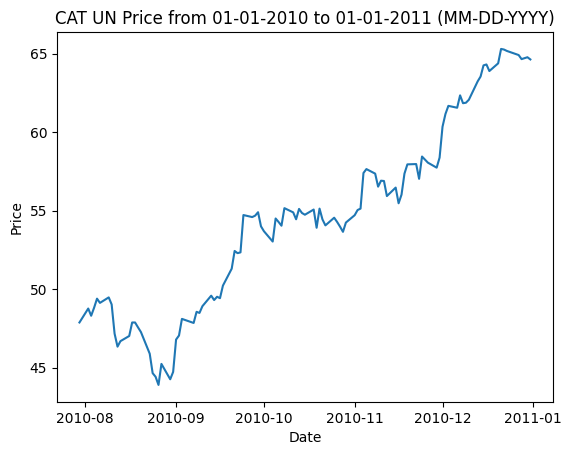

Date
2010-08-03   -0.009479
2010-08-04    0.010504
2010-08-05    0.011813
2010-08-06   -0.005482
2010-08-09    0.007100
                ...   
2010-12-27   -0.003997
2010-12-28   -0.004013
2010-12-29    0.000928
2010-12-30    0.000927
2010-12-31   -0.002163
Name: CAT UN, Length: 106, dtype: float64


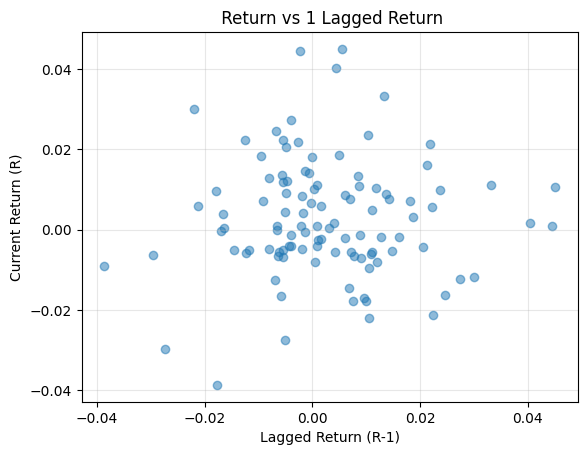

AR(1) Coefficient: 0.01453790653432952
AR(1) p-value: 0.9970126227100061
         lb_stat  lb_pvalue
1   2.907441e-07   0.999570
5   1.789010e+00   0.877501
10  7.353702e+00   0.691684
20  1.482878e+01   0.786120
1     0.999570
5     0.877501
10    0.691684
20    0.786120
Name: lb_pvalue, dtype: float64


/Users/nmjos/Documents/University/COMPSCI 399 Capstone/.venv/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/nmjos/Documents/University/COMPSCI 399 Capstone/.venv/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/nmjos/Documents/University/COMPSCI 399 Capstone/.venv/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/nmjos/Documents/University/COMPSCI 399 Capstone/.venv/lib/python3.10/site-packages/statsmodel

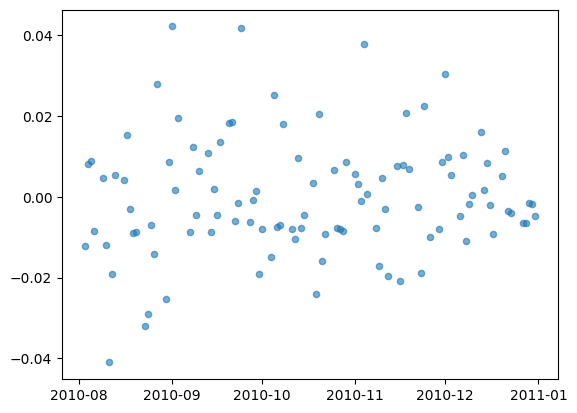

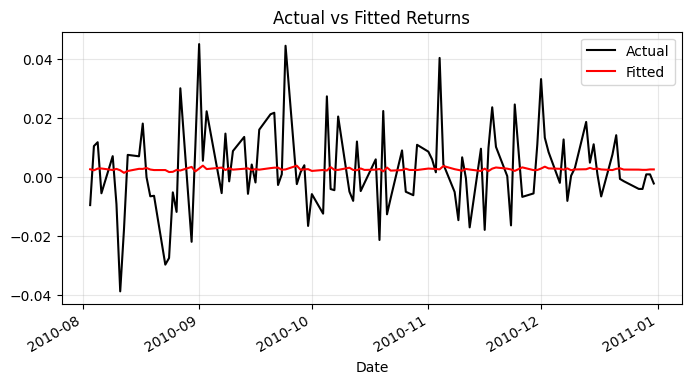

In [ ]:
def plot_stock_price(stock, start_date, end_date):
    plt.plot(stock.index, stock.values, label="Stock Price")
    plt.xlabel("Date")
    plt.ylabel("Price")
    plt.title(f"{stock.name} Price from {start_date} to {end_date} (MM-DD-YYYY)")
    plt.show()

def get_stock_data(stock_symbol, start_date, end_date):
    stock = df[stock_symbol]
    stock = stock.loc[pd.to_datetime(start_date):pd.to_datetime(end_date)]
    return stock


def plot_return_lagged_return(returns, returns_lagged, lag):
    
    plt.scatter(returns, returns_lagged, alpha=0.5)
    plt.xlabel(f"Lagged Return (R-{lag})")
    plt.ylabel("Current Return (R)")
    plt.title(f" Return vs {lag} Lagged Return")
    plt.grid(True, alpha=0.3)
    plt.show()

def plot_acf_pacf(series, lags=40):
 
    plt.subplot(1,2,1)
    plot_acf(series, lags=lags, ax=plt.gca())
    plt.title(f"ACF of {series.name}")
    plt.subplot(1,2,2)
    plot_pacf(series, lags=lags, ax=plt.gca())
    plt.title(f"PACF of {series.name}")
    plt.tight_layout()
    plt.show()


def get_stock_return_window(stock, window):
    sampled_prices = stock.iloc[::window]
    returns = np.log(sampled_prices).diff().dropna()
    return returns

def ar_lagged_return(stock_ticker, lag, window, start_date, end_date, ARIMA_order=(1,0,1)):
    stock = get_stock_data(stock_ticker, start_date, end_date)
    plot_stock_price(stock, start_date, end_date)
    
    
    returns = get_stock_return_window(stock, window)
    returns_lagged = returns.shift(1).dropna()
    returns= returns.iloc[1:]

    print(returns)
    
    plot_return_lagged_return(returns, returns_lagged, lag)
    # plot_acf_pacf(returns, lags=20)




    model = ARIMA(returns, order=ARIMA_order).fit()
    # print(model.summary())
    
    b_coef = model.params.get('ar.L1')
    print(f"AR(1) Coefficient: {b_coef}")
    b_pvalue = model.pvalues.get('ar.L1')
    print(f"AR(1) p-value: {b_pvalue}")

    fitted = model.fittedvalues   

    residual = model.resid
    plt.scatter(residual.index, residual.values, alpha=0.6, s=20)
    lb = acorr_ljungbox(residual, lags=[1,5,10, 20], return_df=True)
    print(lb)
    print(lb['lb_pvalue'])

    plt.figure(figsize=(8,4))
    returns.plot(label="Actual", color="black")
    fitted.plot(label="Fitted", color="red")
    plt.title("Actual vs Fitted Returns")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()
    
    
    

    return model

ar_lagged_return(stock_ticker = "KO UN", lag = 1, window = 1, start_date="01-01-2010", end_date="01-01-2011")

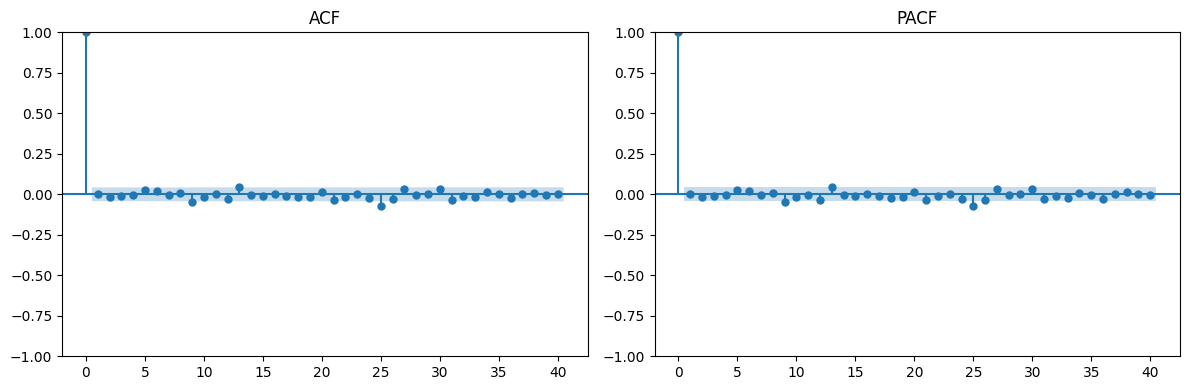

In [553]:
def plot_acf_pacf(series, lags=40):
    series = pd.to_numeric(series, errors='coerce').dropna()
    if isinstance(series, pd.DataFrame):
        raise ValueError("Pass a 1-D Series, not a DataFrame.")
    lags = min(lags, len(series)-2)
    if lags < 1:
        raise ValueError("Not enough data for ACF/PACF.")
    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plot_acf(series, lags=lags, ax=plt.gca())
    plt.title("ACF")
    plt.subplot(1,2,2)
    plot_pacf(series, lags=lags, ax=plt.gca(), method="ywm")
    plt.title("PACF")
    plt.tight_layout()
    plt.show()

# Use returns (stationary) instead of raw prices:
stock = get_stock_data("VZ UN", "2010", "2019")
returns = np.log(stock).diff().dropna()   # or stock.pct_change().dropna()
plot_acf_pacf(returns)


/Users/nmjos/Documents/University/COMPSCI 399 Capstone/.venv/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/nmjos/Documents/University/COMPSCI 399 Capstone/.venv/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/nmjos/Documents/University/COMPSCI 399 Capstone/.venv/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
/Users/nmjos/Documents/University/COMPSCI 399 Capstone/.venv/lib/python3.10/site-packages/statsmodel

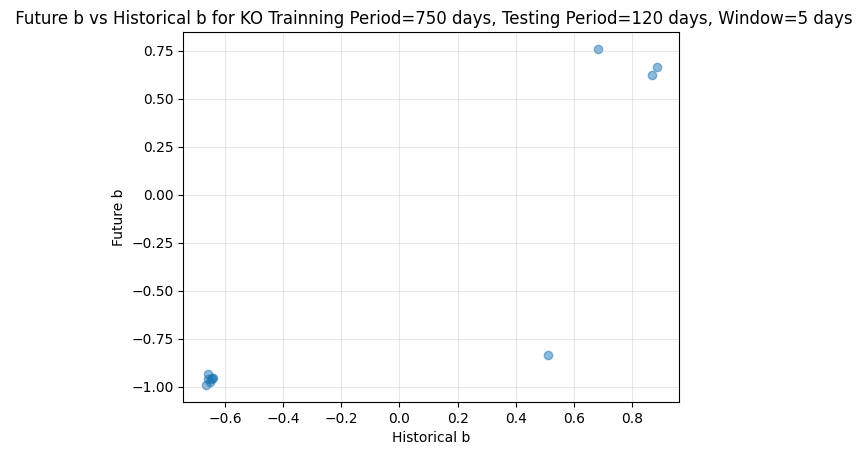

In [570]:
def get_stock_return(stock_ticker, window):
    stock = df[stock_ticker]
    prices = stock.iloc[::window]
    returns = np.log(prices).diff().dropna()
    return returns


def check_coefficients_significance(model, alpha=0.05, lb_lags=[1]):
    model_params = model.params
    model_pvalues = model.pvalues

    b_coef = model_params.get('ar.L1')
    b_pvalue = model_pvalues.get('ar.L1')

    residual = model.resid
    lb = acorr_ljungbox(residual, lags=lb_lags, return_df=True)
    lb_pvalues = lb['lb_pvalue']
    
    # Check if residuals are white noise
    for p_value in lb_pvalues:
        if p_value < alpha:
            return None  # Residuals are not white noise
    
    # Check if coefficient is statistically significant
    if b_pvalue is not None and b_pvalue < alpha:
        return b_coef
    else:
        return None # Coefficient is not statistically significant

def plot_b_lagged_b(train_b, test_b):
    
    plt.scatter(train_b, test_b, alpha=0.5)
    plt.xlabel(f"Historical b")
    plt.ylabel("Future b")
    plt.title(f" Future b vs Historical b for KO Trainning Period=750 days, Testing Period=120 days, Window=5 days")
    plt.grid(True, alpha=0.3)
    plt.show()


def historical_b(stock_ticker, trainning_period, testing_period, window, ARIMA_order=(1,0,1), p_value_threshold=0.05):
    
    historical_b_values = []
    # Get returns in the desired window, e.g 1-day, 5-day, etc.
    returns = get_stock_return(stock_ticker, window)

    # Calculate number of days for training and testing sets, e.g if window=5, 60 days = 12 data points
    training_days = trainning_period // window
    testing_days = testing_period // window

    lb_lags = [1]
    for i in range(5, min(testing_days, training_days), 5):
        lb_lags.append(i)
 

    for start in range(0, len(returns) - testing_days - training_days + 1):
        train_period_returns = returns.iloc[start: start + training_days]
        test_period_returns = returns.iloc[start + training_days: start + training_days + testing_days]

        training_model = ARIMA(train_period_returns, order=ARIMA_order).fit()
        training_b_coef = check_coefficients_significance(training_model, alpha=p_value_threshold, lb_lags=lb_lags)

        testing_model = ARIMA(test_period_returns, order=ARIMA_order).fit()
        testing_b_coef = check_coefficients_significance(testing_model, alpha=p_value_threshold, lb_lags=lb_lags)

        if training_b_coef is not None and testing_b_coef is not None:
            date = test_period_returns.index[-1]
            
            historical_b_values.append({
                "date": date,
                "train_b": training_b_coef,
                "test_b": testing_b_coef,
            })

    if not historical_b_values:
        print("No significant b coefficients found in any period.")
        return pd.DataFrame() 
    
    return pd.DataFrame(historical_b_values).set_index("date").sort_index()



vz_b = historical_b_values = historical_b(stock_ticker="KO UN", trainning_period=750, testing_period=120, window=5, ARIMA_order=(1,0,1), p_value_threshold=0.05)
train_b = vz_b['train_b']
test_b = vz_b['test_b']
plot_b_lagged_b(train_b, test_b)




        


    




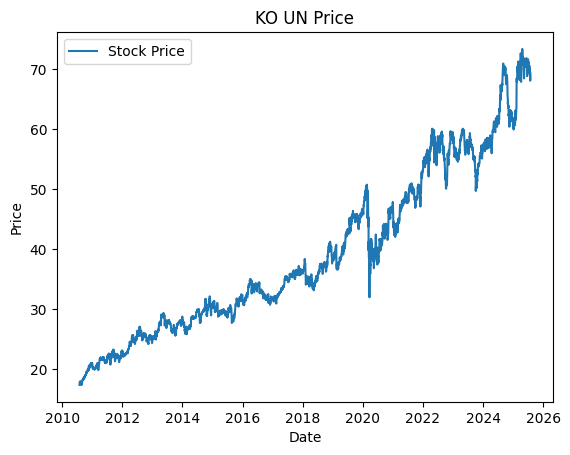

In [572]:
stock = df["KO UN"]
plt.plot(stock.index, stock.values, label="Stock Price")
plt.xlabel("Date")
plt.ylabel("Price")
plt.title(f"KO UN Price")
plt.legend()
plt.show()
